# ДЗ 1. Обнаружение сетевых атак в инфраструктуре (NSL-KDD)

Ютик Семён Иванович, РИ-431001

## 1. Постановка задачи

### 1.1 Бизнес-постановка

Когда мы проводим пентест внутренней инфраструктуры, мы сами генерируем много «плохого» трафика: сканируем порты (nmap), обходим подсети пингами,
подбираем пароли к сервисам, пробуем повысить привилегии. Хорошая защита у заказчика должна такую активность замечать.
На практике в SOC сидят люди, которые не могут глазами разобрать миллионы соединений, поэтому нужна автоматика.

Бизнес-задача: сделать детектор сетевых атак (элемент IDS) — по описанию сетевого соединения автоматически определять,
нормальное это соединение или атака, и поднимать алерт для аналитика SOC.

Для нас как для пентестеров такая модель полезна ещё и тем, что по ней можно понять, какие наши действия «шумные» и будут замечены, а какие нет.

### 1.2 Постановка ML-задачи

- Объект — одно сетевое соединение (TCP-сессия / UDP- или ICMP-обмен), описанное набором признаков.
- Целевая переменная y: 0 — нормальное соединение, 1 — атака.
- Тип задачи: бинарная классификация (обучение с учителем).

В данных есть и конкретный тип атаки (neptune, nmap, satan, …), поэтому дальше задачу можно расширить
до многоклассовой (определять категорию атаки: DoS / Probe / R2L / U2R), но основная постановка — бинарная.

### 1.3 Набор данных

Используем NSL-KDD — классический открытый датасет для задач обнаружения вторжений.
Файлы взяты с GitHub: https://github.com/jmnwong/NSL-KDD-Dataset

- KDDTrain+.txt — обучающая выборка, ~126 тыс. соединений
- KDDTest+.txt — тестовая выборка, ~22.5 тыс. соединений
- 41 признак + название атаки + difficulty (служебный столбец — сколько моделей авторов датасета ошиблись на объекте, как признак его не используем)

Признаки делятся на группы:
- базовые признаки соединения: duration, protocol_type, service, flag, src_bytes, dst_bytes …
- content признаки (что происходило внутри сессии): num_failed_logins, logged_in, root_shell, num_file_creations …
- time-based traffic признаки (окно 2 секунды): count, srv_count, serror_rate, rerror_rate …
- host-based признаки (последние 100 соединений к тому же хосту): dst_host_count, dst_host_srv_count …

Атаки в датасете делятся на 4 категории:
- DoS — отказ в обслуживании (neptune = SYN flood, smurf, teardrop, back …)
- Probe — разведка, ровно то, что мы делаем в начале пентеста (nmap, portsweep, ipsweep, satan)
- R2L — удалённый доступ без учётки (guess_passwd, ftp_write, imap, warezclient …)
- U2R — повышение привилегий до root (buffer_overflow, rootkit, perl …)

Объём данных (~150 тыс. размеченных соединений) достаточен для обучения и честной проверки модели.

## Импорт библиотек

In [1]:
import os
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.cbook import boxplot_stats
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

sns.set_theme()
pd.set_option('display.max_columns', 50)

## Загрузка данных

В файлах нет заголовка, поэтому названия столбцов задаём сами (по описанию датасета).

In [2]:
columns = [
    'duration', 'protocol_type', 'service', 'flag', 'src_bytes', 'dst_bytes', 'land',
    'wrong_fragment', 'urgent', 'hot', 'num_failed_logins', 'logged_in', 'num_compromised',
    'root_shell', 'su_attempted', 'num_root', 'num_file_creations', 'num_shells',
    'num_access_files', 'num_outbound_cmds', 'is_host_login', 'is_guest_login', 'count',
    'srv_count', 'serror_rate', 'srv_serror_rate', 'rerror_rate', 'srv_rerror_rate',
    'same_srv_rate', 'diff_srv_rate', 'srv_diff_host_rate', 'dst_host_count',
    'dst_host_srv_count', 'dst_host_same_srv_rate', 'dst_host_diff_srv_rate',
    'dst_host_same_src_port_rate', 'dst_host_srv_diff_host_rate', 'dst_host_serror_rate',
    'dst_host_srv_serror_rate', 'dst_host_rerror_rate', 'dst_host_srv_rerror_rate',
    'attack', 'difficulty'
]

# если файлы лежат рядом с ноутбуком - читаем их, иначе качаем с GitHub
URL = 'https://raw.githubusercontent.com/jmnwong/NSL-KDD-Dataset/master/'
base = '' if os.path.exists('KDDTrain+.txt') else URL

train = pd.read_csv(base + 'KDDTrain+.txt', header=None, names=columns)
test = pd.read_csv(base + 'KDDTest+.txt', header=None, names=columns)
train.shape, test.shape

((125973, 43), (22544, 43))

Добавим целевую переменную (0 - норма, 1 - атака) и категорию атаки.

In [3]:
attack_category = {
    'normal': 'normal',
    # DoS
    'neptune': 'DoS', 'smurf': 'DoS', 'back': 'DoS', 'teardrop': 'DoS', 'pod': 'DoS', 'land': 'DoS',
    'apache2': 'DoS', 'processtable': 'DoS', 'mailbomb': 'DoS', 'udpstorm': 'DoS',
    # Probe
    'satan': 'Probe', 'ipsweep': 'Probe', 'portsweep': 'Probe', 'nmap': 'Probe',
    'mscan': 'Probe', 'saint': 'Probe',
    # R2L
    'guess_passwd': 'R2L', 'ftp_write': 'R2L', 'imap': 'R2L', 'phf': 'R2L', 'multihop': 'R2L',
    'warezmaster': 'R2L', 'warezclient': 'R2L', 'spy': 'R2L', 'xlock': 'R2L', 'xsnoop': 'R2L',
    'snmpguess': 'R2L', 'snmpgetattack': 'R2L', 'httptunnel': 'R2L', 'sendmail': 'R2L', 'named': 'R2L',
    'worm': 'R2L',
    # U2R
    'buffer_overflow': 'U2R', 'loadmodule': 'U2R', 'rootkit': 'U2R', 'perl': 'U2R',
    'sqlattack': 'U2R', 'xterm': 'U2R', 'ps': 'U2R',
}

for d in [train, test]:
    d['target'] = (d['attack'] != 'normal').astype(int)
    d['category'] = d['attack'].map(attack_category)

assert train['category'].isna().sum() == 0 and test['category'].isna().sum() == 0, 'есть атаки без категории'

## 2. Выбор метрики

Модель ошибается двумя способами:
- FN (пропуск атаки) — атакующий (или мы на пентесте) спокойно сканирует сеть / подбирает пароли, а SOC об этом не знает. Это самая дорогая ошибка.
- FP (ложный алерт) — аналитик тратит время на разбор нормального трафика. Если таких алертов много, на них перестают смотреть (alert fatigue), так что совсем игнорировать FP тоже нельзя.

Accuracy не подходит: в обучающей выборке классы примерно сбалансированы, но в реальной сети атак сильно меньше, чем нормального трафика,
и модель «всё нормально» будет иметь высокую accuracy и при этом ничего не ловить (пример из лекции про спам).

Основная метрика — F2-мера (fbeta, beta=2), дополнительно смотрим отдельно Recall и Precision, а также ROC-AUC (качество разделения без привязки к порогу).

Обоснование: пропуск атаки для бизнеса дороже ложного срабатывания, поэтому recall важнее precision — F2 даёт recall больший вес, но не позволяет
модели «кричать на всё подряд», т.к. при падении precision метрика тоже падает. Recall и Precision по отдельности смотрим, чтобы понимать,
сколько атак пропускаем и сколько мусора получает SOC, а порог классификации потом можно подобрать через стоимость ошибок
Cost = Cost_FP * FP + Cost_FN * FN, как в лекции про метрики.

## 3. EDA

### 3.1 Базовые характеристики

In [4]:
train.head()

,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,num_failed_logins,logged_in,num_compromised,root_shell,su_attempted,num_root,num_file_creations,num_shells,num_access_files,num_outbound_cmds,is_host_login,is_guest_login,count,srv_count,serror_rate,srv_serror_rate,rerror_rate,srv_rerror_rate,same_srv_rate,diff_srv_rate,srv_diff_host_rate,dst_host_count,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,attack,difficulty,target,category
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,2,2,0.0,0.0,0.0,0.0,1.00,0.00,0.00,150,25,0.17,0.03,0.17,0.00,0.00,0.00,0.05,0.00,normal,20,0,normal
1,0,udp,other,SF,146,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,13,1,0.0,0.0,0.0,0.0,0.08,0.15,0.00,255,1,0.00,0.60,0.88,0.00,0.00,0.00,0.00,0.00,normal,15,0,normal
2,0,tcp,private,S0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,123,6,1.0,1.0,0.0,0.0,0.05,0.07,0.00,255,26,0.10,0.05,0.00,0.00,1.00,1.00,0.00,0.00,neptune,19,1,DoS
3,0,tcp,http,SF,232,8153,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,5,5,0.2,0.2,0.0,0.0,1.00,0.00,0.00,30,255,1.00,0.00,0.03,0.04,0.03,0.01,0.00,0.01,normal,21,0,normal
4,0,tcp,http,SF,199,420,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,30,32,0.0,0.0,0.0,0.0,1.00,0.00,0.09,255,255,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,normal,21,0,normal


In [ ]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 125973 entries, 0 to 125972
Data columns (total 45 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   duration                     125973 non-null  int64  
 1   protocol_type                125973 non-null  str    
 2   service                      125973 non-null  str    
 3   flag                         125973 non-null  str    
 4   src_bytes                    125973 non-null  int64  
 5   dst_bytes                    125973 non-null  int64  
 6   land                         125973 non-null  int64  
 7   wrong_fragment               125973 non-null  int64  
 8   urgent                       125973 non-null  int64  
 9   hot                          125973 non-null  int64  
 10  num_failed_logins            125973 non-null  int64  
 11  logged_in                    125973 non-null  int64  
 12  num_compromised              125973 non-null  int64  
 13  root_shell

Все признаки числовые, кроме трёх категориальных: protocol_type, service, flag (+ наши attack и category).

In [6]:
train.isna().sum().sum(), test.isna().sum().sum()

(np.int64(0), np.int64(0))

In [7]:
train.duplicated().sum(), test.duplicated().sum()

(np.int64(0), np.int64(0))

Пропусков и дубликатов нет — авторы NSL-KDD уже почистили данные (в исходном KDD99 было очень много дублей).
С этой стороны предобработка не нужна.

In [8]:
train.nunique().sort_values().head(12)

num_outbound_cmds    1
land                 2
root_shell           2
logged_in            2
is_host_login        2
is_guest_login       2
target               2
wrong_fragment       3
num_shells           3
su_attempted         3
protocol_type        3
urgent               4
dtype: int64

- num_outbound_cmds имеет одно значение (всегда 0) — признак бесполезен, его нужно удалить.
- Много бинарных признаков (land, logged_in, root_shell, is_guest_login …) — это флаги событий внутри сессии.

In [9]:
train.describe().T

,count,mean,std,min,25%,50%,75%,max
duration,125973.0,287.144650,2.604515e+03,0.0,0.00,0.00,0.00,4.290800e+04
src_bytes,125973.0,45566.743000,5.870331e+06,0.0,0.00,44.00,276.00,1.379964e+09
dst_bytes,125973.0,19779.114421,4.021269e+06,0.0,0.00,0.00,516.00,1.309937e+09
land,125973.0,0.000198,1.408607e-02,0.0,0.00,0.00,0.00,1.000000e+00
wrong_fragment,125973.0,0.022687,2.535300e-01,0.0,0.00,0.00,0.00,3.000000e+00
urgent,125973.0,0.000111,1.436603e-02,0.0,0.00,0.00,0.00,3.000000e+00
hot,125973.0,0.204409,2.149968e+00,0.0,0.00,0.00,0.00,7.700000e+01
num_failed_logins,125973.0,0.001222,4.523914e-02,0.0,0.00,0.00,0.00,5.000000e+00
logged_in,125973.0,0.395736,4.890101e-01,0.0,0.00,0.00,1.00,1.000000e+00
num_compromised,125973.0,0.279250,2.394204e+01,0.0,0.00,0.00,0.00,7.479000e+03


Что видно из describe:
- src_bytes и dst_bytes: медиана — десятки/сотни байт, а максимум ~1.3 млрд. Распределения с очень тяжёлым хвостом, нужно логарифмировать.
- duration у большинства соединений = 0 (75% квантиль тоже 0), отдельные сессии длятся десятки тысяч секунд.
- Признаки с окончанием _rate лежат в [0, 1] — это доли, они уже нормированы.
- count, srv_count, dst_host_count и т.п. — счётчики до 511 / 255, масштаб сильно отличается от rate-признаков,
  поэтому для линейных моделей понадобится масштабирование (StandardScaler).
- Content-признаки (num_failed_logins, root_shell, num_shells …) почти всегда 0 — у них очень мало информации, но для редких атак R2L/U2R они могут быть важны.

### 3.2 Целевая переменная

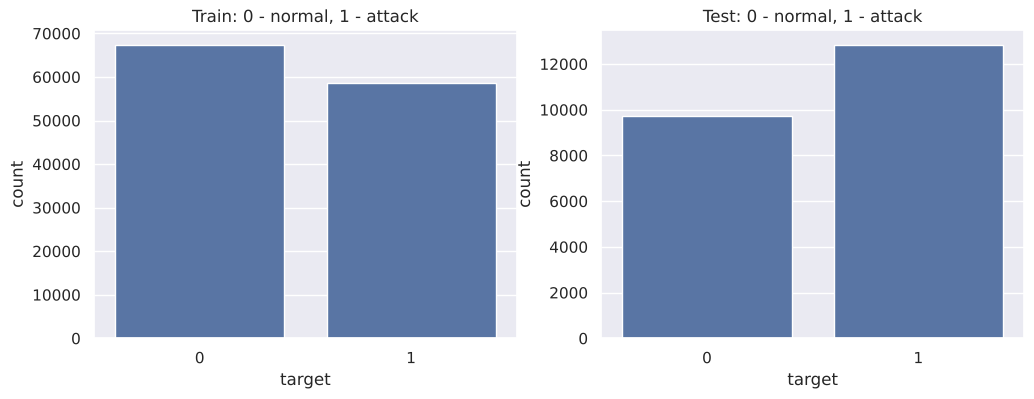

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(x=train['target'], ax=axes[0])
axes[0].set_title('Train: 0 - normal, 1 - attack')
sns.countplot(x=test['target'], ax=axes[1])
axes[1].set_title('Test: 0 - normal, 1 - attack');

In [11]:
pd.DataFrame({
    'train': train['target'].value_counts(normalize=True),
    'test': test['target'].value_counts(normalize=True),
}).round(3)

,train,test
target,,
0,0.535,0.431
1,0.465,0.569


В train ~47% атак, в test ~57%. То есть по бинарной цели классы примерно сбалансированы.
Важно понимать, что это свойство датасета, а не реальности: в живой сети атак гораздо меньше.
Поэтому метрику выбирали не accuracy, а F2/recall/precision — они не так зависят от доли классов.

In [12]:
order = ['normal', 'DoS', 'Probe', 'R2L', 'U2R']
cat_stat = pd.DataFrame({
    'train': train['category'].value_counts(),
    'test': test['category'].value_counts(),
}).reindex(order)
cat_stat['train_%'] = (cat_stat['train'] / cat_stat['train'].sum() * 100).round(2)
cat_stat['test_%'] = (cat_stat['test'] / cat_stat['test'].sum() * 100).round(2)
cat_stat

,train,test,train_%,test_%
category,,,,
normal,67343,9711,53.46,43.08
DoS,45927,7458,36.46,33.08
Probe,11656,2421,9.25,10.74
R2L,995,2887,0.79,12.81
U2R,52,67,0.04,0.30


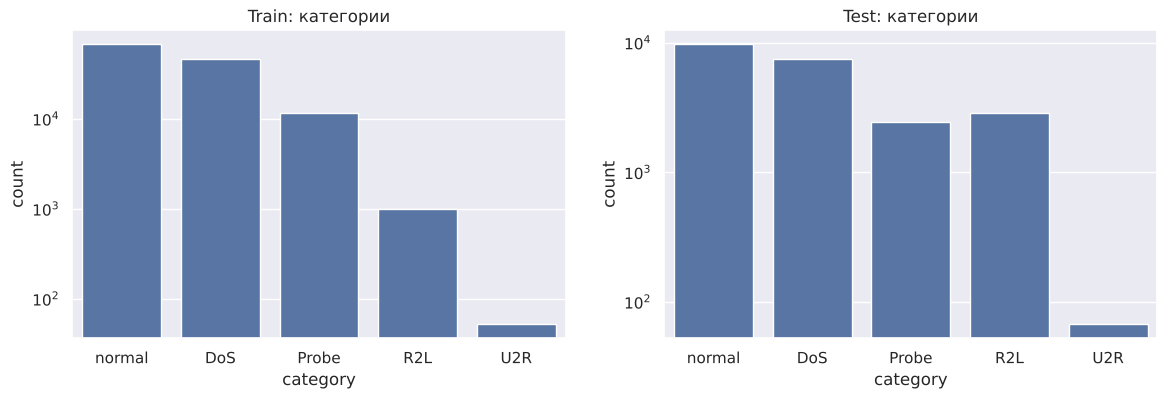

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.countplot(x=train['category'], order=order, ax=axes[0])
axes[0].set_title('Train: категории')
axes[0].set_yscale('log')
sns.countplot(x=test['category'], order=order, ax=axes[1])
axes[1].set_title('Test: категории')
axes[1].set_yscale('log');

(ось Y логарифмическая, иначе U2R просто не видно)

- Внутри атак сильный дисбаланс: DoS — большинство, U2R — всего 52 записи в train (0.04%), R2L — менее 1%.
- В test доля R2L намного больше (~12%), чем в train. Значит, модель, обученная на train, скорее всего будет плохо ловить R2L
  (подбор паролей и т.п.) — это нужно учитывать при оценке и, возможно, делать взвешивание классов.

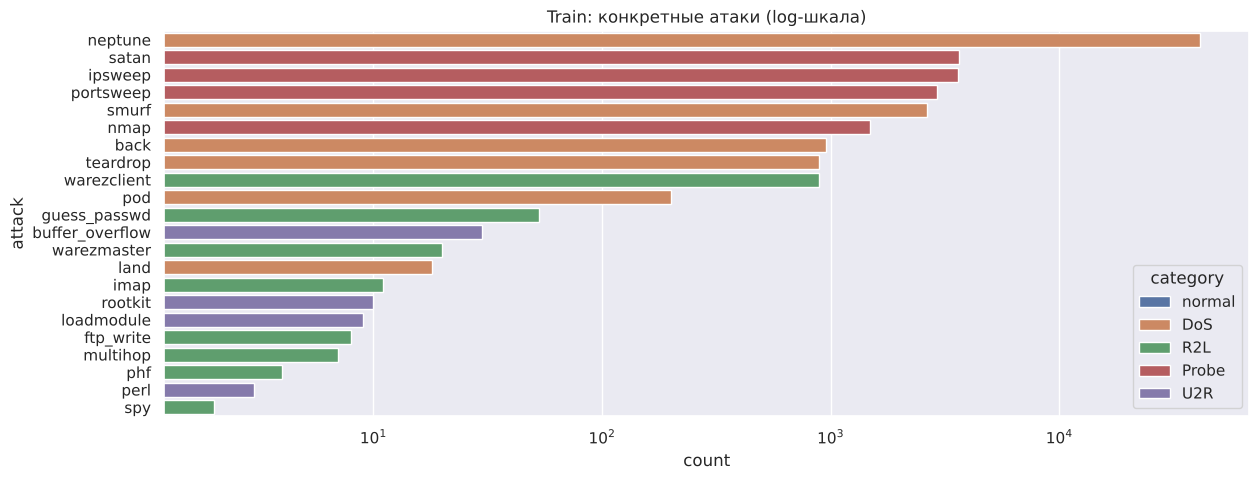

In [14]:
plt.figure(figsize=(14, 5))
sns.countplot(y=train.loc[train['target'] == 1, 'attack'],
              order=train.loc[train['target'] == 1, 'attack'].value_counts().index,
              hue=train['category'], dodge=False)
plt.xscale('log')
plt.title('Train: конкретные атаки (log-шкала)');

Один neptune (SYN flood) — это 41 тыс. записей, больше половины всех атак. Модель будет в основном учиться на нём.
Из Probe хорошо представлены все «пентестерские» сканы: satan, ipsweep, portsweep, nmap.

In [15]:
new_attacks = set(test['attack']) - set(train['attack'])
print('Атаки, которых нет в train:', len(new_attacks))
print(sorted(new_attacks))
print('Доля таких записей в test:', round(test['attack'].isin(new_attacks).mean(), 3))

Атаки, которых нет в train: 17
['apache2', 'httptunnel', 'mailbomb', 'mscan', 'named', 'processtable', 'ps', 'saint', 'sendmail', 'snmpgetattack', 'snmpguess', 'sqlattack', 'udpstorm', 'worm', 'xlock', 'xsnoop', 'xterm']
Доля таких записей в test: 0.166


Важный вывод: в test есть 17 типов атак, которых нет в train (около 17% тестовой выборки), например mscan, saint, apache2, snmpguess.
Это хорошо имитирует реальность — атакующий использует новые техники. Значит качество на test будет заметно ниже, чем на валидации из train,
и для честной оценки нужно использовать именно KDDTest+, а не только случайный сплит train.

### 3.3 Категориальные признаки

In [16]:
cat_cols = ['protocol_type', 'service', 'flag']
train[cat_cols].describe()

,protocol_type,service,flag
count,125973,125973,125973
unique,3,70,11
top,tcp,http,SF
freq,102689,40338,74945


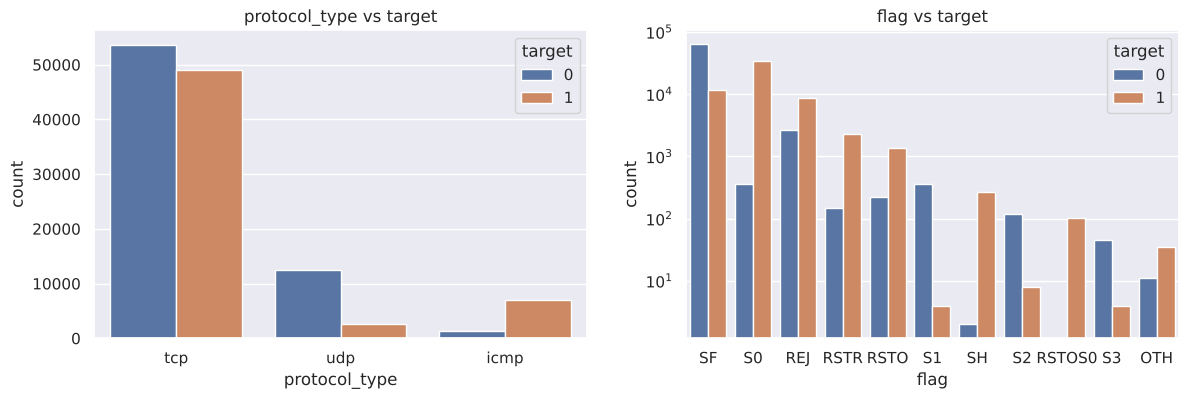

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.countplot(data=train, x='protocol_type', hue='target', ax=axes[0])
axes[0].set_title('protocol_type vs target')
sns.countplot(data=train, x='flag', hue='target', ax=axes[1],
              order=train['flag'].value_counts().index)
axes[1].set_title('flag vs target')
axes[1].set_yscale('log');

In [18]:
pd.crosstab(train['flag'], train['target'], normalize='index').round(3).style.background_gradient(cmap='summer_r')

target,0,1
flag,,
OTH,0.239000,0.761000
REJ,0.240000,0.760000
RSTO,0.140000,0.860000
RSTOS0,0.000000,1.000000
RSTR,0.060000,0.940000
S0,0.010000,0.990000
S1,0.989000,0.011000
S2,0.937000,0.063000
S3,0.918000,0.082000


Флаги очень информативны, и это понятно с точки зрения работы TCP:
- S0 — отправлен SYN, ответа нет. 99% таких соединений — атаки: это SYN flood (neptune) и SYN-сканирование (nmap -sS).
- REJ — соединение отклонено (RST на SYN), т.е. порт закрыт. ~76% атак — типичный результат сканирования портов.
- RSTR, RSTOS0, SH — тоже почти всегда атаки (обрывы/нестандартные последовательности флагов при сканировании).
- SF — нормально установленное и закрытое соединение, здесь в основном норма (но 15% атак тоже есть — R2L/U2R работают через нормальные сессии).

Вывод: flag нужно обязательно использовать (через One-Hot Encoding, значений всего 11).

In [19]:
pd.crosstab(train['protocol_type'], train['target'], normalize='index').round(3)

target,0,1
protocol_type,,
icmp,0.158,0.842
tcp,0.522,0.478
udp,0.829,0.171


ICMP — 84% атак (ping sweep ipsweep, smurf, pod). UDP наоборот в основном нормальный (DNS — domain_u).

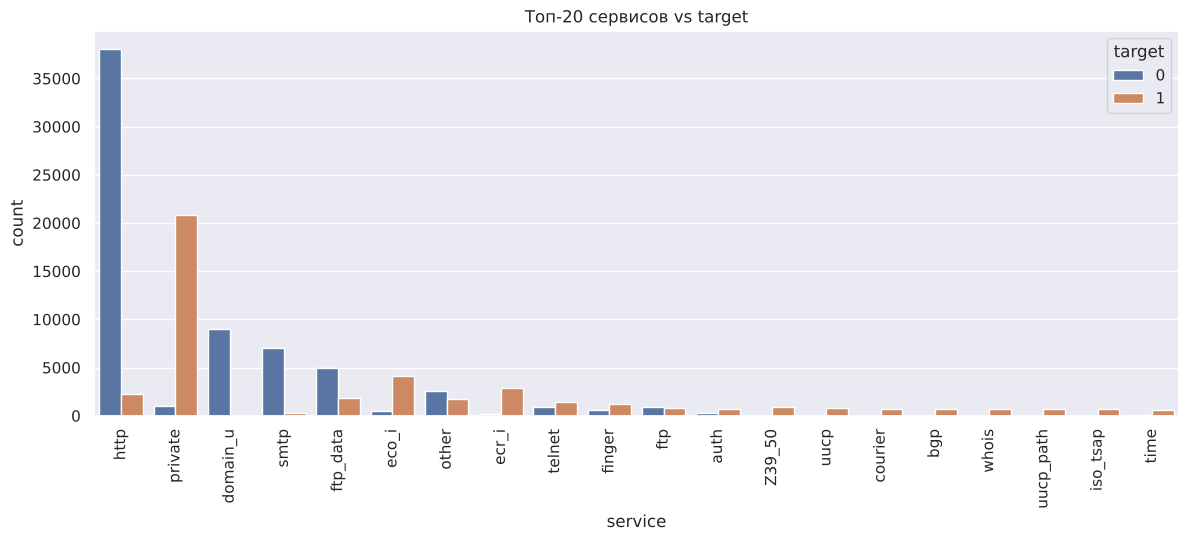

In [20]:
top_services = train['service'].value_counts().head(20).index
plt.figure(figsize=(14, 5))
sns.countplot(data=train[train['service'].isin(top_services)], x='service', hue='target', order=top_services)
plt.xticks(rotation=90)
plt.title('Топ-20 сервисов vs target');

In [21]:
service_stat = train.groupby('service')['target'].agg(['count', 'mean']).sort_values('count', ascending=False)
service_stat.head(15)

,count,mean
service,,
http,40338,0.056746
private,21853,0.955063
domain_u,9043,0.000995
smtp,7313,0.038835
ftp_data,6860,0.273469
eco_i,4586,0.891627
other,4359,0.402615
ecr_i,3077,0.938252
telnet,2353,0.610285


- service — 70 значений, распределение сильно неравномерное (http, private, domain_u, smtp …).
- private — почти одни атаки: так помечаются нестандартные порты, а при сканировании и SYN flood пакеты идут на всё подряд.
- http, domain_u, smtp — в основном норма.
- eco_i/ecr_i (ICMP echo) — ping sweep и smurf.

Для service One-Hot даст 70 столбцов — это допустимо, но можно объединить редкие сервисы в other или использовать target/frequency encoding.

In [22]:
print('Сервисы в test, которых нет в train:', set(test['service']) - set(train['service']))

Сервисы в test, которых нет в train: set()


### 3.4 Числовые признаки

In [23]:
num_cols = train.select_dtypes(include='number').drop(columns=['target', 'difficulty']).columns
len(num_cols)

38

Распределения объёма трафика и длительности. Из-за огромного разброса строим в логарифме (log1p, т.к. много нулей).

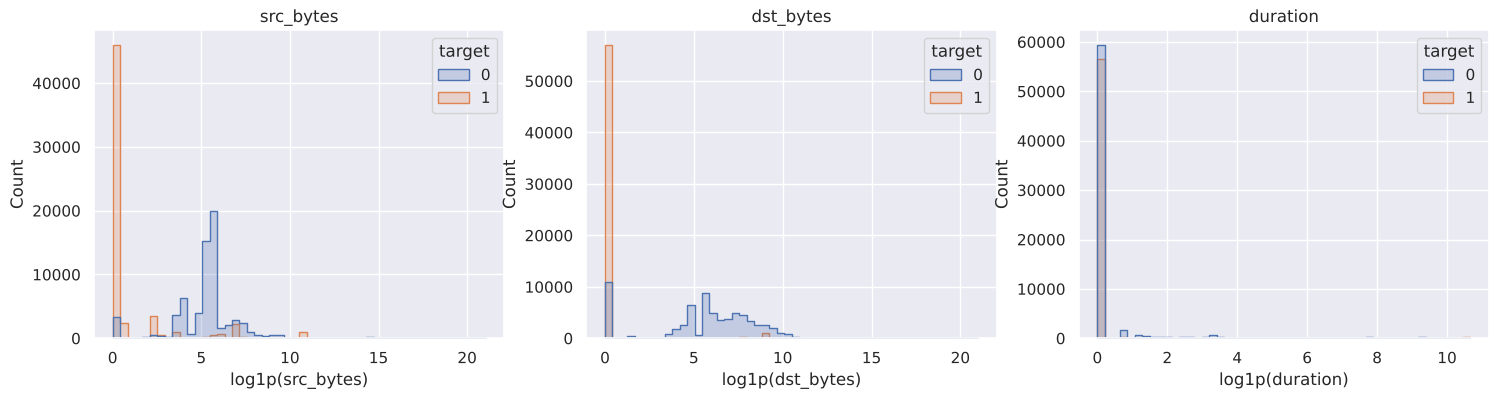

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, col in zip(axes, ['src_bytes', 'dst_bytes', 'duration']):
    sns.histplot(data=train, x=np.log1p(train[col]), hue='target', bins=50, ax=ax, element='step')
    ax.set_xlabel(f'log1p({col})')
    ax.set_title(col)

In [25]:
train.groupby('target')[['src_bytes', 'dst_bytes', 'duration']].median()

,src_bytes,dst_bytes,duration
target,,,
0,233.0,379.0,0.0
1,0.0,0.0,0.0


- У атак медиана src_bytes и dst_bytes = 0: при SYN flood / сканировании данные вообще не передаются, только служебные пакеты.
- У нормальных соединений — сотни байт (обычные HTTP-запросы, DNS).
- duration почти у всех 0 — признак слабый, но длинные сессии бывают у R2L (например, warezclient).

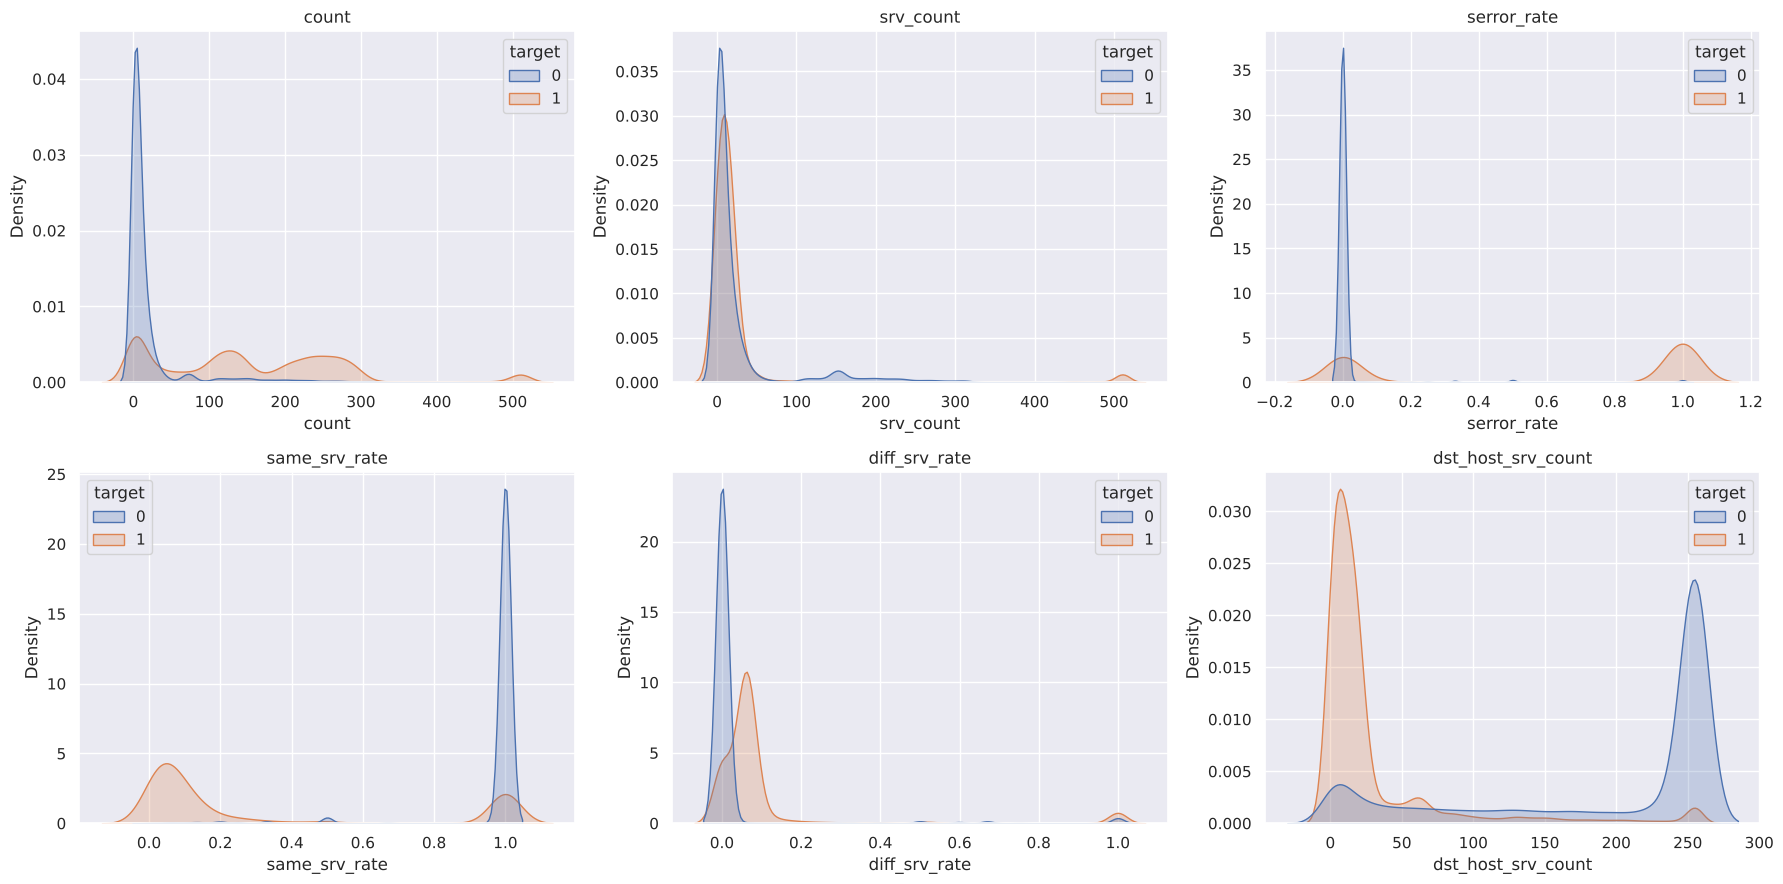

In [26]:
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, col in zip(axes.flatten(), ['count', 'srv_count', 'serror_rate', 'same_srv_rate', 'diff_srv_rate', 'dst_host_srv_count']):
    sns.kdeplot(data=train, x=col, hue='target', common_norm=False, fill=True, ax=ax)
    ax.set_title(col)
plt.tight_layout();

Признаки «окна 2 секунды» и host-based хорошо разделяют классы:
- count — сколько соединений к тому же хосту за последние 2 секунды. У атак сдвинут вправо: флуд и сканер шлют много пакетов быстро.
- serror_rate — доля SYN-ошибок. Для атак часто = 1 (тот же S0).
- same_srv_rate — у нормы ≈ 1 (клиент ходит на один сервис), у атак близко к 0 — сканер перебирает разные порты/сервисы.
- diff_srv_rate — доля соединений на разные сервисы, у атак выше.
- dst_host_srv_count — у нормы часто 255 (сервис постоянно используется), у атак маленький.

С точки зрения пентеста это ровно то, чем «светится» nmap со стандартными настройками: много соединений за короткое время на разные порты.

#### Выбросы

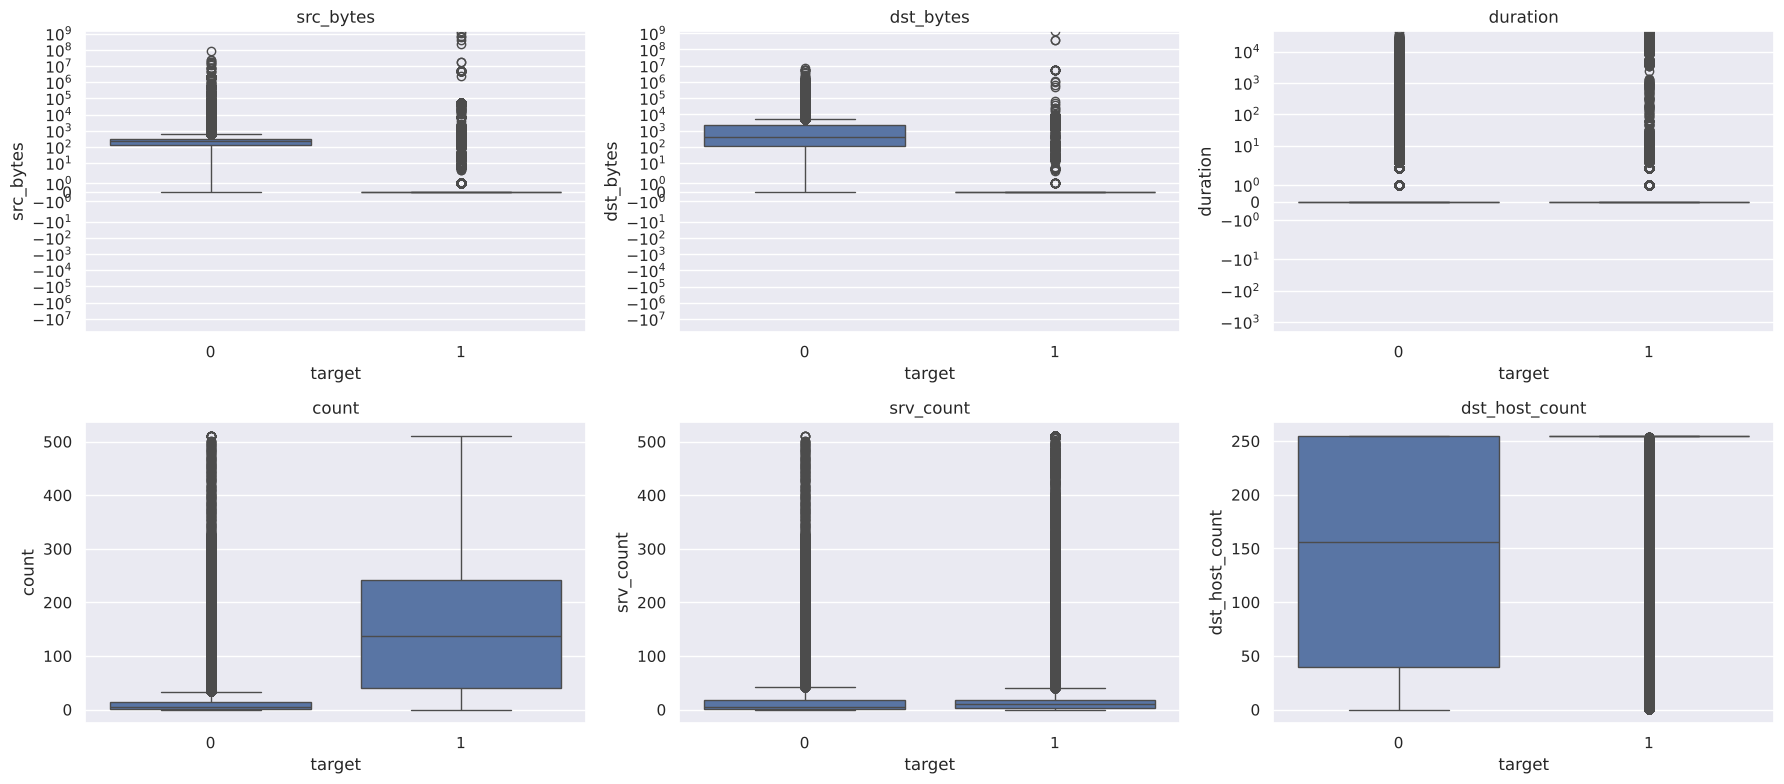

In [27]:
box_cols = ['src_bytes', 'dst_bytes', 'duration', 'count', 'srv_count', 'dst_host_count']
fig, axes = plt.subplots(2, 3, figsize=(18, 8))
for ax, col in zip(axes.flatten(), box_cols):
    sns.boxplot(data=train, x='target', y=col, ax=ax)
    ax.set_title(col)
    if col in ['src_bytes', 'dst_bytes', 'duration']:
        ax.set_yscale('symlog')
plt.tight_layout();

In [28]:
for col in ['src_bytes', 'dst_bytes', 'duration']:
    fliers = boxplot_stats(train[col]).pop(0)['fliers']
    print(f'{col}: выбросов {len(fliers)} ({len(fliers) / len(train):.1%}), максимум {train[col].max():,}')

src_bytes: выбросов 13840 (11.0%), максимум 1,379,963,888
dst_bytes: выбросов 23579 (18.7%), максимум 1,309,937,401
duration: выбросов 10018 (8.0%), максимум 42,908


Выбросов по src_bytes / dst_bytes / duration формально много, но удалять их нельзя — это реальные соединения
(передача больших файлов, долгие сессии), и среди них есть атаки. Лучше применить log1p, а для деревьев масштаб вообще не важен.

In [29]:
train.sort_values('src_bytes', ascending=False)[['protocol_type', 'service', 'flag', 'src_bytes', 'dst_bytes', 'attack']].head(5)

,protocol_type,service,flag,src_bytes,dst_bytes,attack
125429,tcp,ftp,RSTOS0,1379963888,0,portsweep
44527,tcp,private,RSTOS0,1167519497,0,portsweep
60570,tcp,finger,RSTO,693375640,0,portsweep
43486,tcp,discard,RSTOS0,621568663,0,portsweep
1038,tcp,telnet,RSTOS0,381709090,0,portsweep


Интересно: самые большие src_bytes (сотни мегабайт - гигабайт) — у portsweep с флагами RSTO/RSTOS0.
Реальной передачи гигабайта при сканировании портов нет, скорее это артефакт подсчёта байт у оборванных соединений при генерации датасета.
Но для модели это всё равно полезная закономерность, поэтому такие записи не удаляем, просто логарифмируем признак.

#### Content-признаки

In [30]:
content_cols = ['hot', 'num_failed_logins', 'logged_in', 'num_compromised', 'root_shell',
                'su_attempted', 'num_file_creations', 'num_shells', 'num_access_files', 'is_guest_login']
(train.groupby('category')[content_cols].mean().reindex(order)).round(3).style.background_gradient(cmap='summer_r', axis=0)

,hot,num_failed_logins,logged_in,num_compromised,root_shell,su_attempted,num_file_creations,num_shells,num_access_files,is_guest_login
category,,,,,,,,,,
normal,0.231000,0.001000,0.711000,0.507000,0.002000,0.002000,0.022000,0.001000,0.007000,0.013000
DoS,0.040000,0.000000,0.021000,0.019000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
Probe,0.002000,0.000000,0.007000,0.001000,0.000000,0.000000,0.002000,0.000000,0.000000,0.000000
R2L,8.335000,0.056000,0.914000,0.077000,0.006000,0.001000,0.035000,0.004000,0.010000,0.315000
U2R,1.404000,0.019000,0.885000,1.212000,0.500000,0.000000,0.788000,0.135000,0.019000,0.000000


Content-признаки почти бесполезны для DoS и Probe (там сессия даже не устанавливается), но хорошо выделяют редкие классы:
- U2R — высокий root_shell, num_file_creations, num_shells: после эксплойта появляется root-шелл и создаются файлы.
- R2L — is_guest_login и hot (anonymous FTP у warezclient), num_failed_logins у подбора паролей.

Значит, эти признаки нужно оставить, несмотря на то, что почти всегда они равны 0.

### 3.5 Корреляции

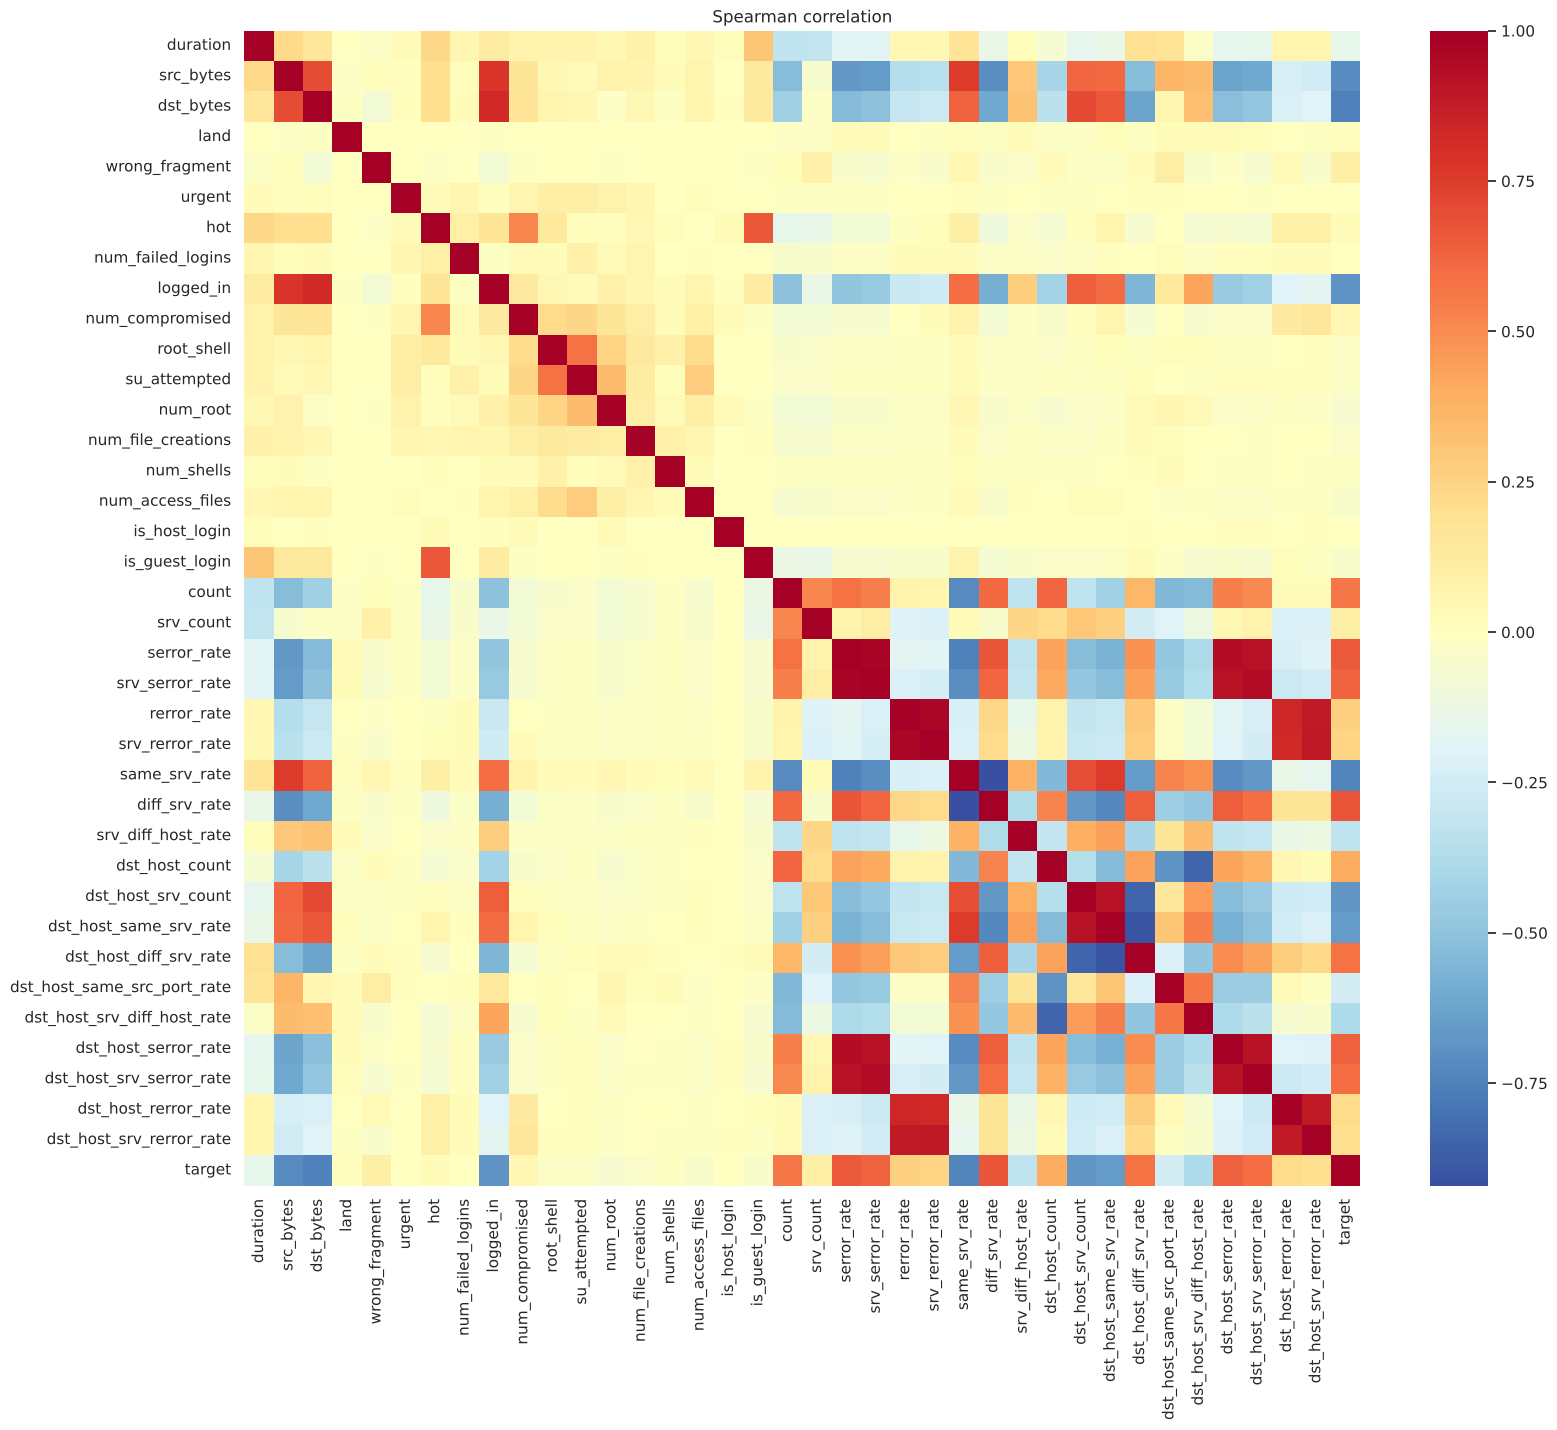

In [31]:
corr = train[list(num_cols) + ['target']].drop(columns=['num_outbound_cmds']).corr(method='spearman')
plt.figure(figsize=(18, 15))
sns.heatmap(corr, cmap='RdYlBu_r', center=0, annot=False)
plt.title('Spearman correlation');

Используем корреляцию Спирмена, а не Пирсона: распределения сильно скошенные и есть выбросы, Пирсон тут будет давать искажённые значения (см. лекцию 3).

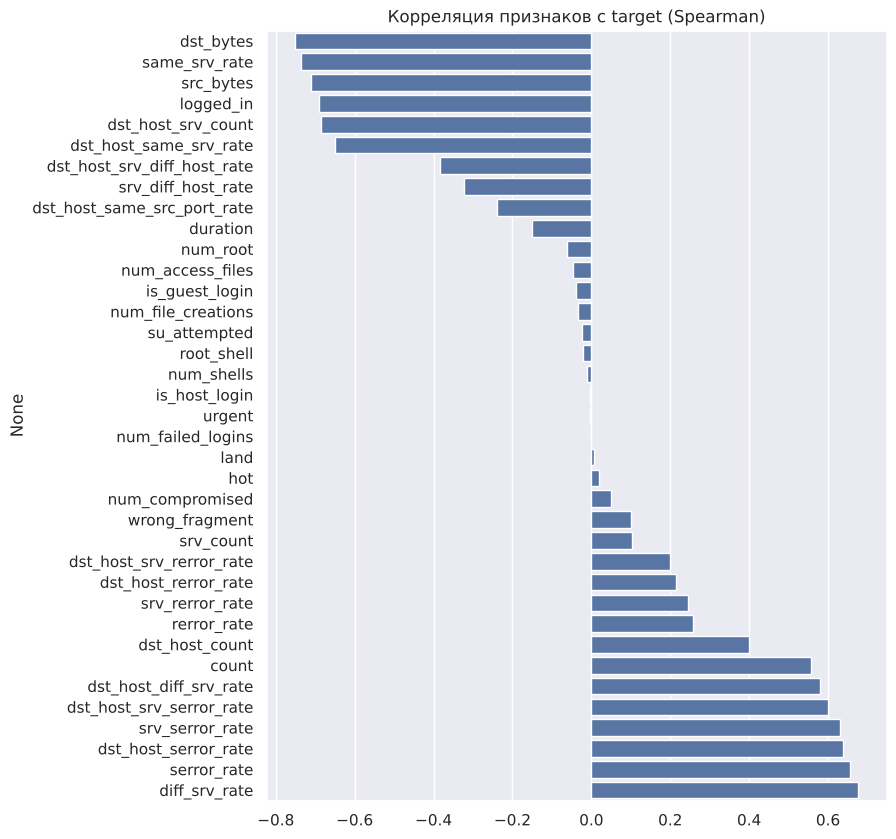

In [32]:
target_corr = corr['target'].drop('target').sort_values()
plt.figure(figsize=(8, 10))
sns.barplot(x=target_corr.values, y=target_corr.index)
plt.title('Корреляция признаков с target (Spearman)');

Сильнее всего с атакой связаны:
- отрицательно: dst_bytes, same_srv_rate, src_bytes, logged_in, dst_host_srv_count — нормальный пользователь логинится, передаёт данные и ходит на один сервис;
- положительно: diff_srv_rate, serror_rate и другие признаки с serror_rate — сканирование и SYN flood.

In [33]:
corr_abs = train[num_cols].drop(columns=['num_outbound_cmds']).corr().abs()
upper = corr_abs.where(np.triu(np.ones(corr_abs.shape), k=1).astype(bool))
high_corr = upper.stack().sort_values(ascending=False)
high_corr[high_corr > 0.95]

num_compromised       num_root                    0.998833
serror_rate           srv_serror_rate             0.993289
rerror_rate           srv_rerror_rate             0.989008
srv_serror_rate       dst_host_srv_serror_rate    0.986252
dst_host_serror_rate  dst_host_srv_serror_rate    0.985052
serror_rate           dst_host_srv_serror_rate    0.981139
                      dst_host_serror_rate        0.979373
srv_serror_rate       dst_host_serror_rate        0.977596
srv_rerror_rate       dst_host_srv_rerror_rate    0.970208
rerror_rate           dst_host_srv_rerror_rate    0.964449
dtype: float64

Есть группы почти дублирующих друг друга признаков (корреляция > 0.95):
- serror_rate, srv_serror_rate, dst_host_serror_rate, dst_host_srv_serror_rate
- rerror_rate, srv_rerror_rate, dst_host_srv_rerror_rate
- num_compromised и num_root

Это логично — они считают одно и то же (ошибки SYN/REJ) в разных окнах. Для линейных моделей это мультиколлинеарность, поэтому
из каждой группы можно оставить 1-2 признака или использовать регуляризацию. Деревьям это мешает меньше.

### 3.6 Сравнение train и test

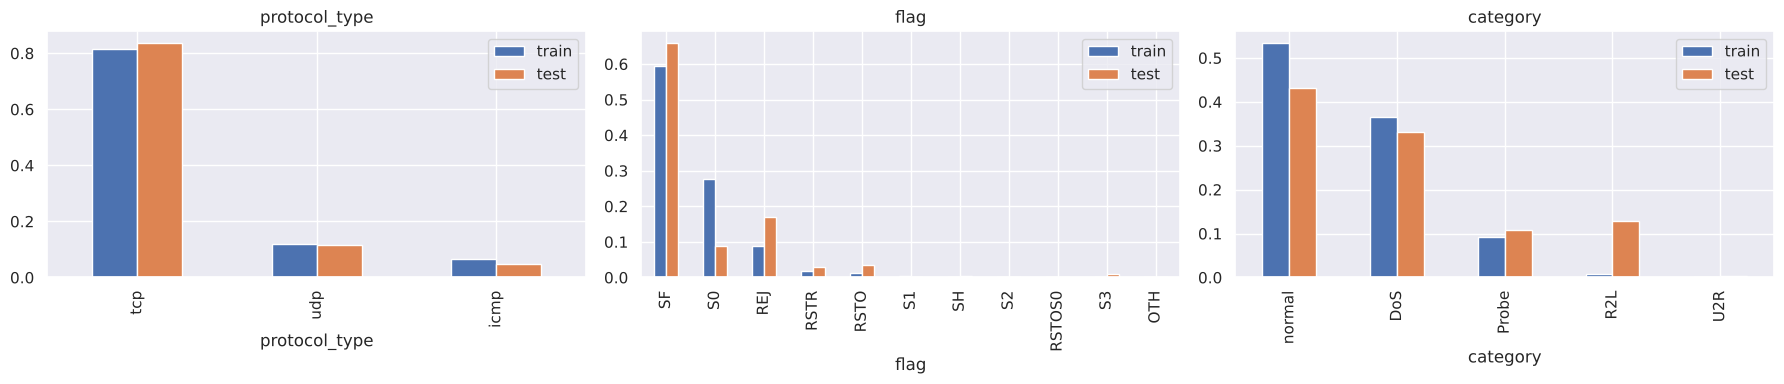

In [34]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, col in zip(axes, ['protocol_type', 'flag', 'category']):
    tmp = pd.concat([
        train[col].value_counts(normalize=True).rename('train'),
        test[col].value_counts(normalize=True).rename('test'),
    ], axis=1).fillna(0)
    tmp.plot(kind='bar', ax=ax)
    ax.set_title(col)
plt.tight_layout();

Распределения в train и test заметно отличаются (меньше S0/DoS и больше R2L в тесте). Это ещё раз говорит о том, что
нельзя оценивать модель только на случайном сплите train — результат будет слишком оптимистичным.

### 3.7 PCA - визуализация классов

Доля объяснённой дисперсии: [0.235 0.14 ]


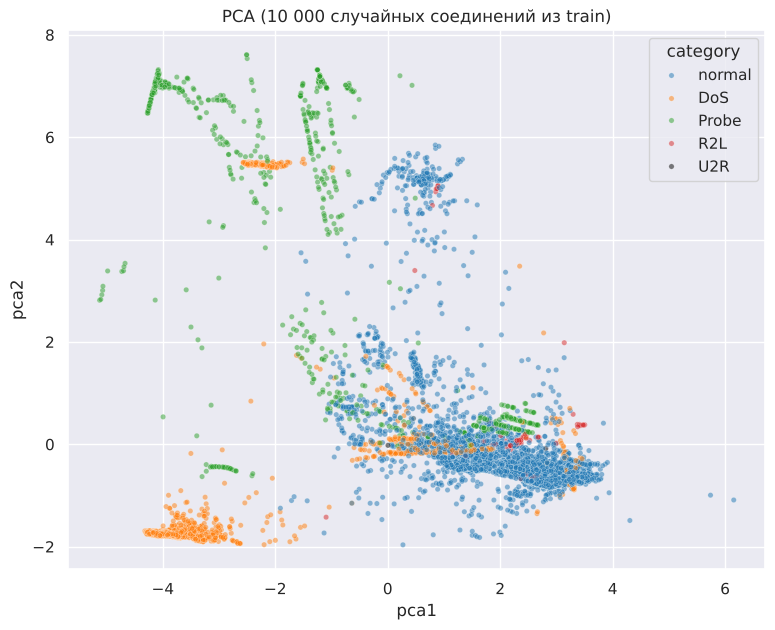

In [35]:
sample = train.sample(10000, random_state=42)
X_num = sample[num_cols].drop(columns=['num_outbound_cmds']).copy()
for col in ['src_bytes', 'dst_bytes', 'duration']:
    X_num[col] = np.log1p(X_num[col])

X_scaled = StandardScaler().fit_transform(X_num)
pca = PCA(n_components=2)
coords = pca.fit_transform(X_scaled)
print('Доля объяснённой дисперсии:', pca.explained_variance_ratio_.round(3))

plt.figure(figsize=(9, 7))
sns.scatterplot(x=coords[:, 0], y=coords[:, 1], hue=sample['category'], hue_order=order, alpha=0.5, s=15,
                palette=['tab:blue', 'tab:orange', 'tab:green', 'tab:red', 'black'])
plt.xlabel('pca1')
plt.ylabel('pca2')
plt.title('PCA (10 000 случайных соединений из train)');

Даже в 2D видно, что normal и DoS образуют отдельные облака, Probe лежит частично отдельно.
R2L и U2R (красные и чёрные точки, их очень мало) находятся внутри облака нормального трафика — их сложнее всего отличить, т.к. на сетевом уровне они выглядят как обычные сессии.

## Выводы по EDA

Данные
- ~126 тыс. соединений в train, 22.5 тыс. в test, 41 признак (38 числовых, 3 категориальных). Пропусков и дубликатов нет.
- По бинарной цели классы сбалансированы (47% / 57% атак), но внутри атак сильный дисбаланс: DoS доминирует (в основном neptune), U2R — 52 записи.
- В test 17 новых типов атак (~17% выборки) и больше R2L — test сложнее и ближе к реальной ситуации.

Что важно с точки зрения ИБ
- Сканирование и DoS отлично видны по сетевым признакам: флаг S0/REJ, высокий serror_rate, много соединений (count) на разные сервисы (diff_srv_rate), 0 байт данных.
- R2L/U2R на сетевом уровне похожи на норму, их выдают только content-признаки (root_shell, num_failed_logins, is_guest_login …). Это самые сложные классы.

План предобработки
1. Удалить num_outbound_cmds (константа) и difficulty (служебный столбец).
2. protocol_type, flag — One-Hot Encoding; service — One-Hot или объединить редкие значения.
3. src_bytes, dst_bytes, duration — log1p, выбросы не удалять.
4. Для линейных моделей — StandardScaler и убрать сильно коррелирующие признаки (группы serror_rate и rerror_rate).
5. Обучать на train, итоговую оценку делать на KDDTest+; учитывать дисбаланс категорий (class_weight).
6. Метрика: F2 + recall/precision + ROC-AUC, порог подбирать с учётом стоимости пропуска атаки.